## Time to get you hands dirty!  Position of a star

You measure the position of a star $N$ times with the *same* telescope i.e. errors are homoscedastic. Let's say the underlying process is Gaussian, the true position is $\mu = 1$ (in suitable units), and the erorrs are $\sigma=0.2$

### Part 1

- Generate fake measurements. Treat each of these observations as an estimate of the true distribution. So we'll center a Gaussian (with the known $\sigma$) at each point. This is the probability of each data point, $p(x_i|\mu,\sigma)$.
  
$\textcolor{blue}{\rm{N.B.}}$: By centering a Gaussian at your data point $x_i$, you are plotting the likelihood function, $\mathcal{L}(\mu | x_i)$. The notebook calls this $p(x_i|\mu,\sigma)$ because, numerically and algebraically, the likelihood function for $\mu$ evaluates to the exact same formula as the probability density function for $x$.

- Plot each of the individual likelihoods separately.  Also plot their product (i.e. the likelihood of the dataset $\{x_i\}$). Make sure the x grid has enough points.
- Just read off the maximum likelihood solution (e.g. using `np.argsort`) 
- Compare it with the MLE estimator derived above

### Part 2

Check the Fisher matrix error estimate makes sense
- do a rough $2^\mathrm{nd}$ order differentation of our log-likelihood function with `np.diff`, 
- divide through by our $\Delta \theta^2$ to get the correct normalization, 
- multiply by $-1$, 
- then take the square root.
- Compare with the Fisher matrix error derived above
- Plot a Gaussian at the measured $\mu$ with this error as the scale to see if it matches the numerical likelihood distribution. (The normalization won't be captured, you can rescale it as you like to check it agrees) 

### Part 3 (optional; not examinable)

Let's make our model more realistic. Our $N$ measurements were taken in different nights, where the sky behaved differently (i.e. errors are heteoscedastic). Let's assume that each measurment has a $\sigma_i$ that is normally distributed with mean $0.2$ and standard deviation $0.05$

- Generalize your code from above to this case

In [1]:
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format='retina'

import scipy.stats
from scipy.stats import norm
from scipy.stats import uniform
from astroML import stats as astroMLstats

In [2]:
def likelihood(x, mu, sigma):
    norm = 1/np.sqrt(2 * np.pi * sigma**2)
    exp = np.exp(-(x - mu)**2/(2*sigma**2))
    p = norm * exp
    return p

### Part 1
I generate 10 points from a normal distribution $N(\mu,\sigma)$ with $\mu =1$ and $\sigma =0.2$. 

Compute the probability $p(x_i|\mu,\sigma)$ and then the joint probability $p({x_i}|\mu,\sigma) = \prod_i p(x_i|\mu,\sigma)$. From here I get the maximum likelihood solution. 

The MLE solution can be found by analitically computing the maximum of the joint likelihood of a set with gaussian errors: $\mu = \frac{1}{N} \sum_i x_i$

In [3]:
N = 10
mu = 1
sigma = 0.2
steps = 2000
x = np.linspace(0, 2, steps)
likelihoods = []

set_x = np.random.normal(mu, sigma, N)

likelihoods = np.array([likelihood(x, xi, sigma) for xi in set_x])

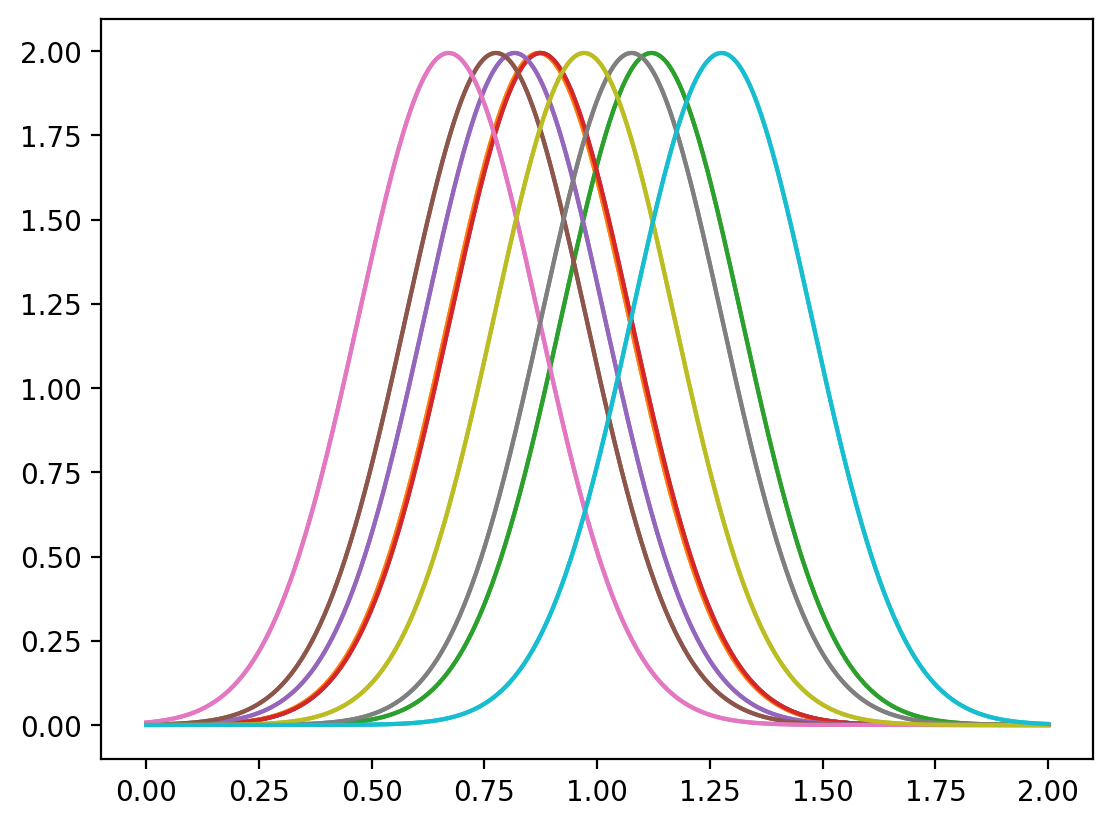

In [5]:
plt.plot(x, likelihoods.T)
plt.show()

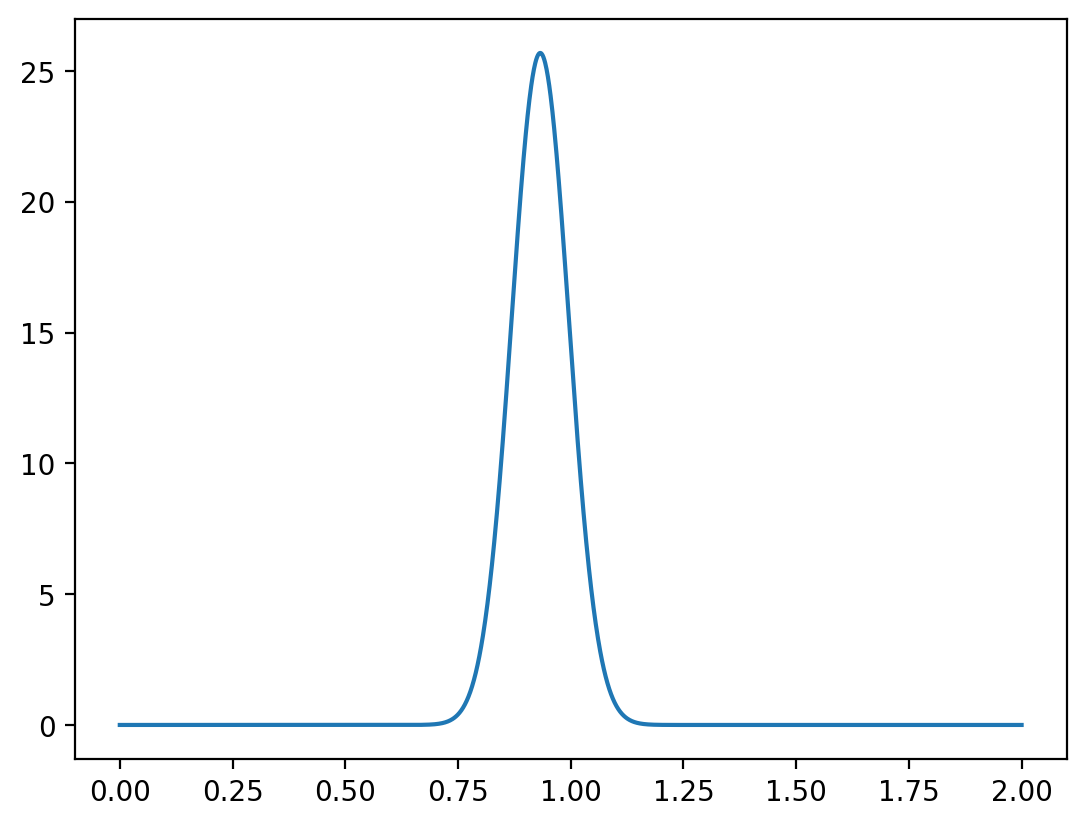

In [6]:
tot_like = np.prod(likelihoods, axis = 0)
plt.plot(x, tot_like)
plt.show()

In [7]:
print(f"The best value from the MLE solution is: {np.sum(set_x)/N}")
print(f"The best value from the maximum likelihood solution is: {x[np.argmax(tot_like)]}")

The best value from the MLE solution is: 0.932465963523258
The best value from the maximum likelihood solution is: 0.9324662331165582


### Part 2
The theoretical Fisher Matrix error for this log-Like is $\sigma_\mu = \frac{\mu}{\sqrt{N}}$

The singol step is $dx = \frac{\Delta L}{\#_{steps}}$, since $\Delta L = 2$, I get $\frac{1}{dx^2} = \frac{\#_{steps}}{2}$

In [8]:
log_like = np.log(tot_like)
log_like_diff = np.diff(log_like, n=2)*(steps/2)**2 

sigma_fish = np.sqrt(-1/log_like_diff[np.argmax(tot_like)+1])

In [9]:
print(f"The theoretical Fischer Matrix error is: {sigma/np.sqrt(N)}")
print(f"The numerical Fischer Matrix error is: {sigma_fish}")

The theoretical Fischer Matrix error is: 0.06324555320336758
The numerical Fischer Matrix error is: 0.06321393042681354


Now we want to compare the numerical likelihood distribution and the normal distribution taking $\mu$ and $\sigma$ from the MLE and Fisher Matrix

In [10]:
mu_t = np.sum(set_x)/N
norm_t = np.random.normal(mu_t, sigma_fish, 5000)

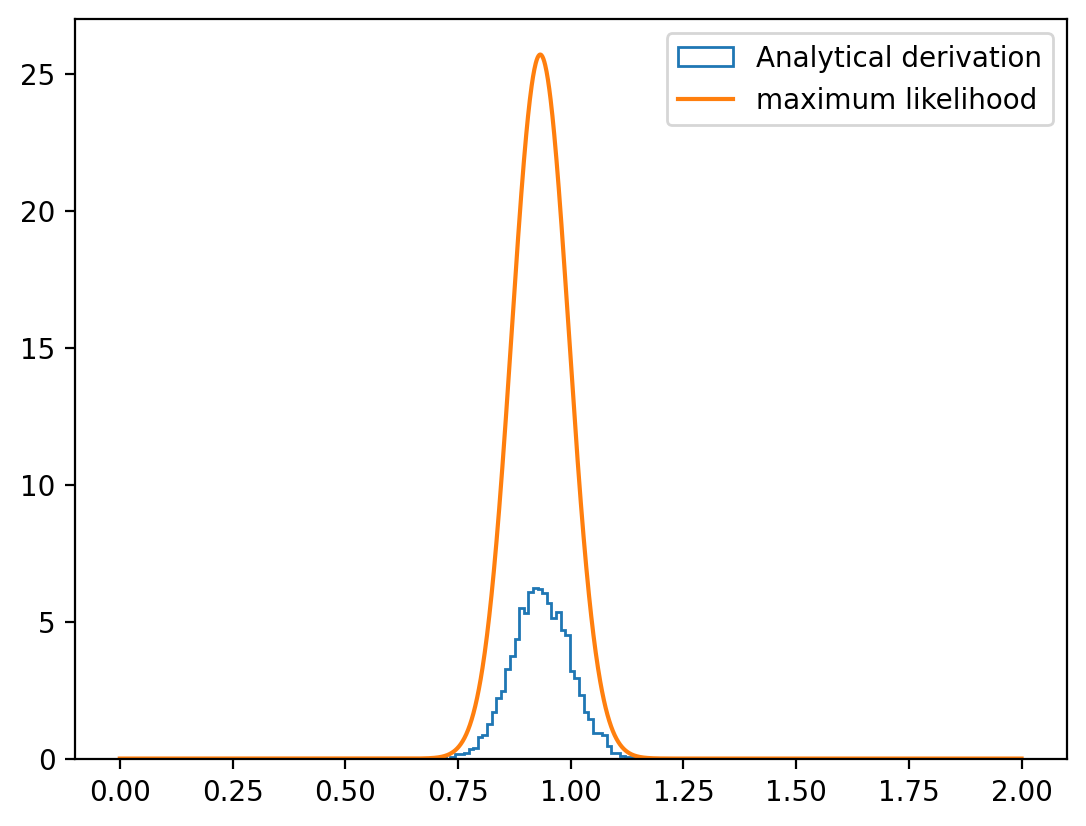

In [11]:
plt.hist(norm_t, bins = "auto", density = True, histtype = 'step', label = 'Analytical derivation')
plt.plot(x, tot_like, label = "maximum likelihood")
plt.legend()
plt.show()

### Part 3
We generalize the code to a heteroscedastic errors: $\sigma$ is normally distributed with $\mu = 0.2$ and and $\sigma=0.05$

In [17]:
sig_mu = 0.2
sig_sig = 0.05

set_sigma = np.random.normal(sig_mu, sig_sig, N)
set_x = np.array([np.random.normal(mu, sigma_i) for sigma_i in set_sigma])

new_likelihoods = np.array([likelihood(x, set_xi, set_sigmai) for set_xi, set_sigmai in zip(set_x, set_sigma)])

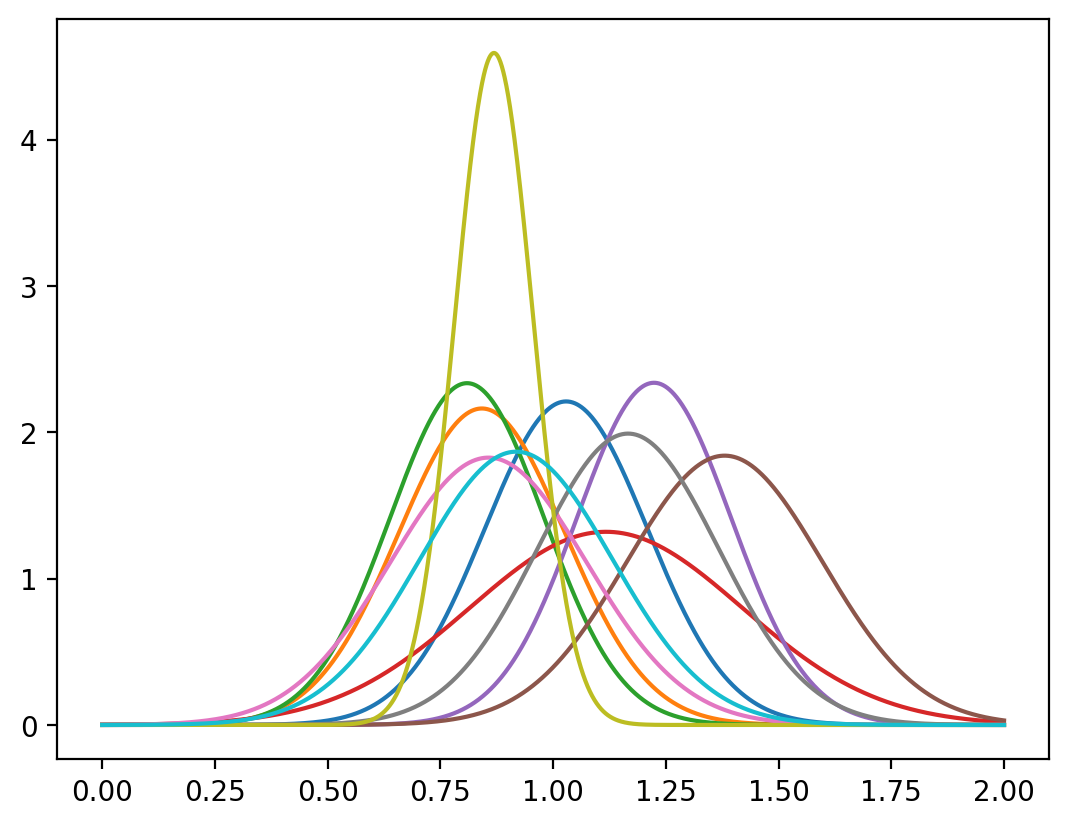

In [18]:
plt.plot(x, new_likelihoods.T)
plt.show()

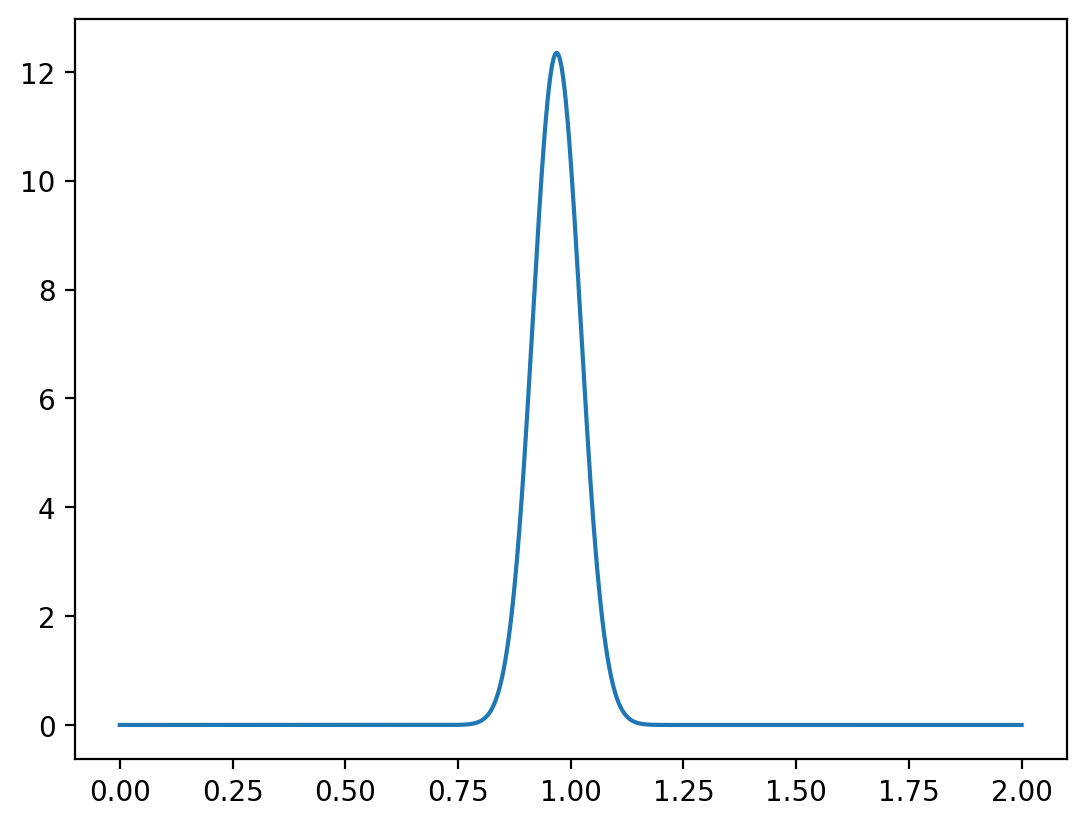

In [19]:
new_tot_like = np.prod(new_likelihoods, axis = 0)
plt.plot(x, new_tot_like)
plt.show()